In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [89]:
df = pd.read_csv("diabetes.csv")
df.shape

(768, 9)

In [15]:
df.sample(5)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
418,1,83,68,0,0,18.2,0.624,27,0
467,0,97,64,36,100,36.8,0.600,25,0
523,9,130,70,0,0,34.2,0.652,45,1
641,4,128,70,0,0,34.3,0.303,24,0
163,2,100,64,23,0,29.7,0.368,21,0


In [16]:
df.info()



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [18]:
df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [25]:
print(df.duplicated().sum())

0


In [26]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [27]:
df.corr()['Outcome']

Pregnancies                 0.221898
Glucose                     0.466581
BloodPressure               0.065068
SkinThickness               0.074752
Insulin                     0.130548
BMI                         0.292695
DiabetesPedigreeFunction    0.173844
Age                         0.238356
Outcome                     1.000000
Name: Outcome, dtype: float64

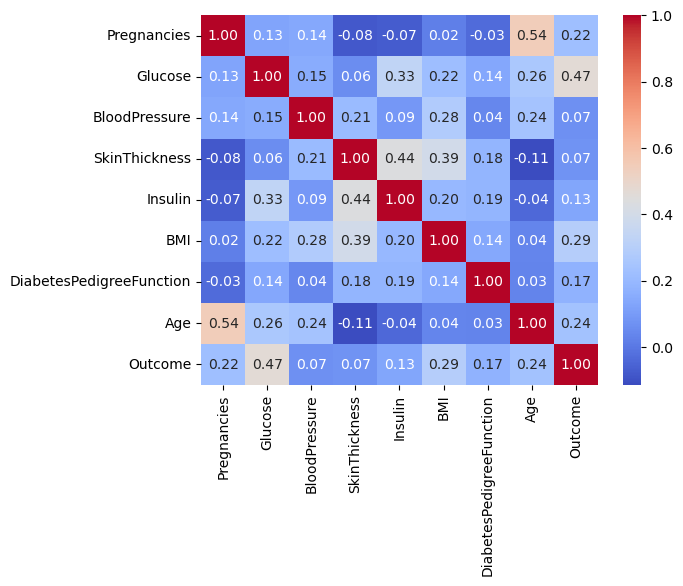

In [31]:
corr_matrix = df.corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.show()

In [38]:
print(len(df[df['BloodPressure'] == 0]))
(df == 0).sum()


35


Pregnancies                 111
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                     500
dtype: int64

Outcome
0    500
1    268
Name: count, dtype: int64


<Axes: xlabel='Outcome', ylabel='count'>

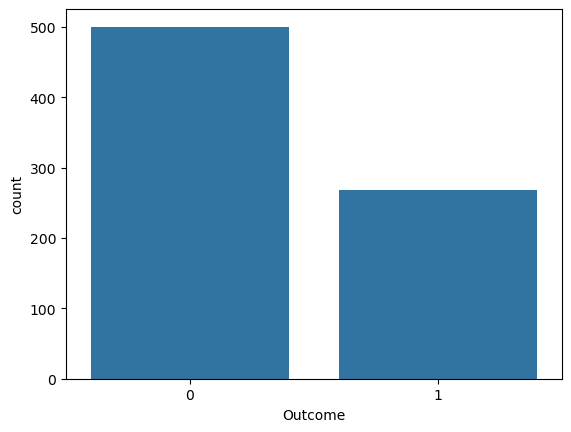

In [44]:
print(df['Outcome'].value_counts())
sns.countplot(data = df, x = 'Outcome')

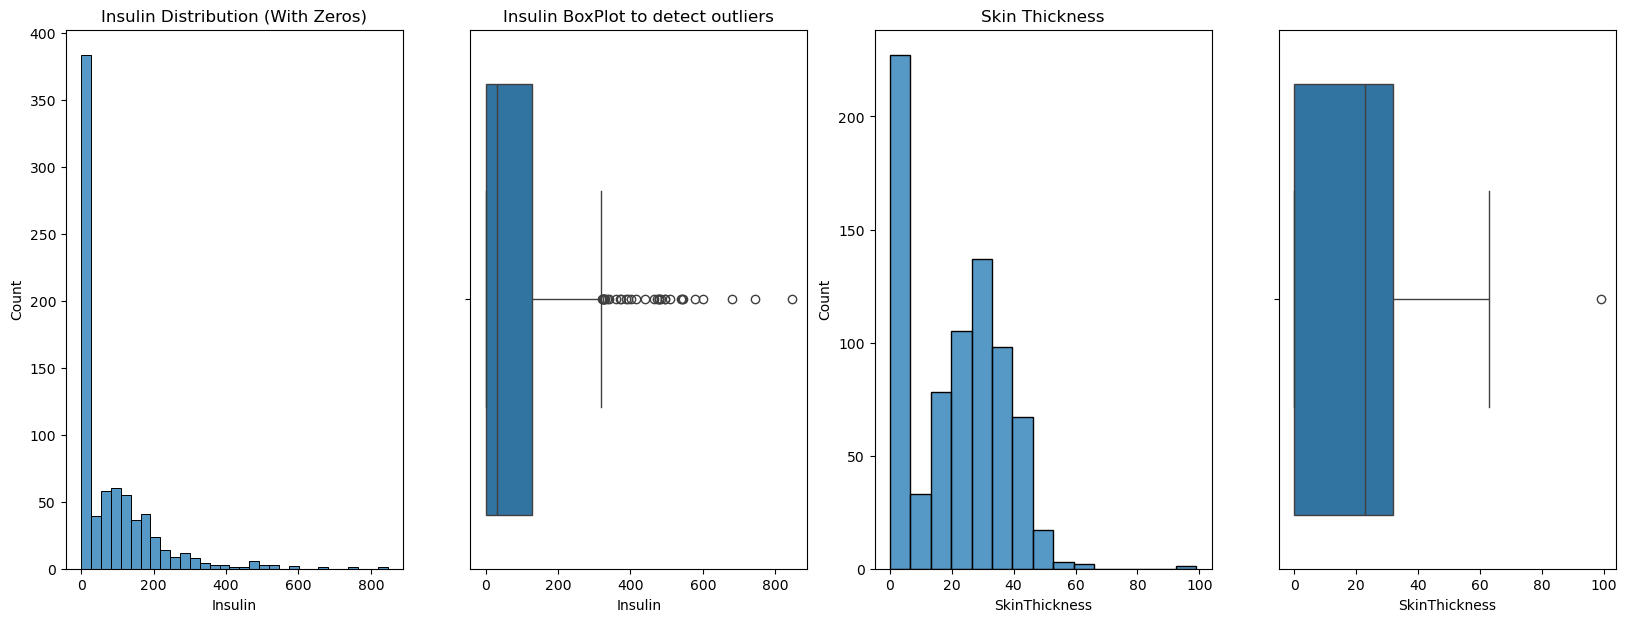

In [62]:
fig, ax = plt.subplots(1,4, figsize = (20,7))
sns.histplot(df['Insulin'], ax = ax[0])
sns.boxplot(data = df, x = 'Insulin' , ax = ax[1])
sns.histplot(df['SkinThickness'], ax = ax[2])
sns.boxplot(data = df, x = 'SkinThickness' , ax = ax[3])

ax[0].set_title('Insulin Distribution (With Zeros)')
ax[1].set_title('Insulin BoxPlot to detect outliers')
ax[2].set_title('Skin Thickness')
plt.show()

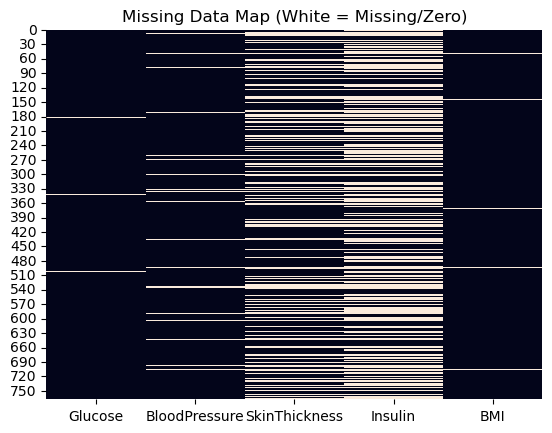

In [65]:

sns.heatmap(df[['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']] == 0, cbar=False)
plt.title('Missing Data Map (White = Missing/Zero)')
plt.show()

<Axes: xlabel='BMI', ylabel='Count'>

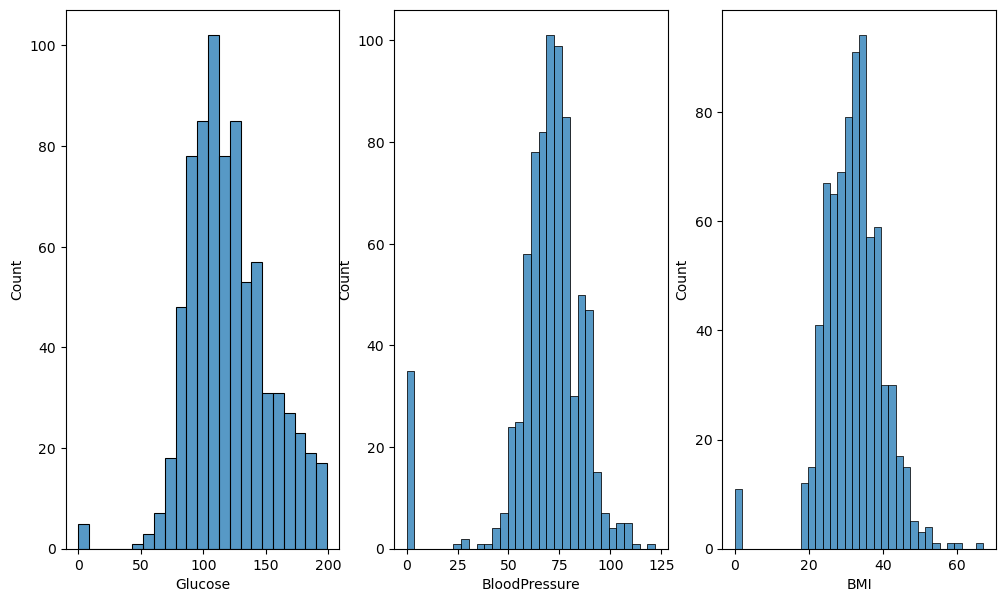

In [79]:
fig, ax = plt.subplots(1,3, figsize=(12,7))
sns.histplot(df['Glucose'], ax = ax[0])
sns.histplot(df['BloodPressure'], ax = ax[1])
sns.histplot(df['BMI'],ax = ax[2])

In [92]:
impossible_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

df[impossible_cols] = df[impossible_cols].replace(0, np.nan)

for col in impossible_cols:
    median_value = df[col].median()
    df[col] = df[col].fillna(median_value)
    print(f"Filled {col} with median: {median_value}")


print("\nMissing values remaining:")
print((df[impossible_cols] == 0).sum())


Filled Glucose with median: 117.0
Filled BloodPressure with median: 72.0
Filled SkinThickness with median: 29.0
Filled Insulin with median: 125.0
Filled BMI with median: 32.3

Missing values remaining:
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
dtype: int64


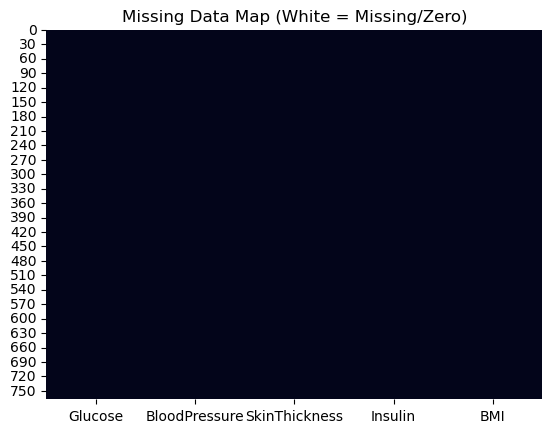

In [93]:

sns.heatmap(df[['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']] == 0, cbar=False)
plt.title('Missing Data Map (White = Missing/Zero)')
plt.show()

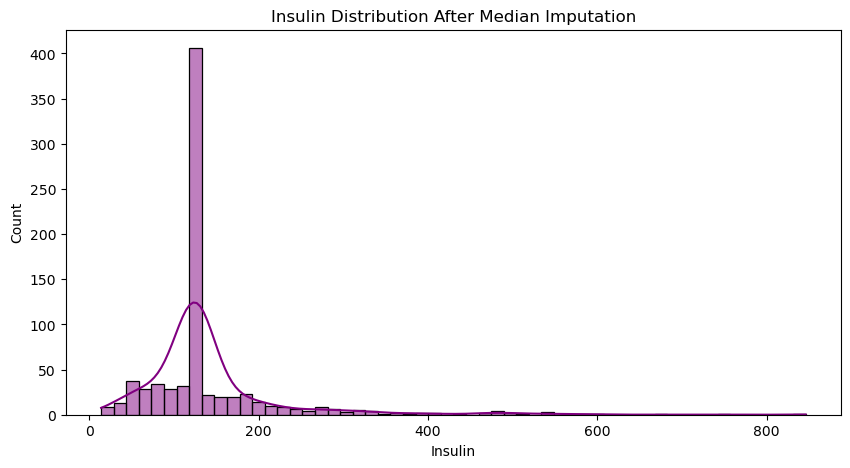

In [83]:
plt.figure(figsize=(10, 5))
sns.histplot(df['Insulin'], kde=True, color='purple')
plt.title('Insulin Distribution After Median Imputation')
plt.show()

In [95]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix,accuracy_score, precision_score, recall_score, f1_score , classification_report
from sklearn.model_selection import train_test_split


X = df.drop('Outcome', axis = 1)
Y = df['Outcome']

x_train,x_test, y_train,y_test = train_test_split(
X,Y,
random_state = 42
)

model_1 = LogisticRegression(max_iter=1000)

model_1.fit(x_train,y_train)

y_predict = model_1.predict(x_test)
print("Before Droping Insulin")
print( classification_report(y_test,y_predict))


Before Droping Insulin
              precision    recall  f1-score   support

           0       0.79      0.81      0.80       123
           1       0.65      0.61      0.63        69

    accuracy                           0.74       192
   macro avg       0.72      0.71      0.71       192
weighted avg       0.74      0.74      0.74       192



In [88]:
df = df.drop("Insulin", axis = 1)

X = df.drop('Outcome', axis = 1)
Y = df['Outcome']

x_train,x_test, y_train,y_test = train_test_split(
X,Y,
random_state = 42
)


model_1 = LogisticRegression(max_iter=1000)

model_1.fit(x_train,y_train)

y_predict = model_1.predict(x_test)

print("After Droping Insulin")
print( classification_report(y_test,y_predict))

After Droping Insulin
              precision    recall  f1-score   support

           0       0.77      0.80      0.79       123
           1       0.62      0.58      0.60        69

    accuracy                           0.72       192
   macro avg       0.70      0.69      0.70       192
weighted avg       0.72      0.72      0.72       192



In [107]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

scaler.fit(x_train)
x_train_scaled = scaler.transform(x_train)
x_test_scaled = scaler.transform(x_test)

model_scaled = LogisticRegression(max_iter=1000)
model_scaled.fit(x_train_scaled, y_train)

y_predict_scaled = model_scaled.predict(x_test_scaled)
y_predict_scaled_train = model_scaled.predict(x_train_scaled)
print("Without Using class_weight parameter")
print("Results After Feature Scaling:")
print(classification_report(y_test, y_predict_scaled))

Without Using class_weight parameter
Results After Feature Scaling:
              precision    recall  f1-score   support

           0       0.79      0.81      0.80       123
           1       0.65      0.61      0.63        69

    accuracy                           0.74       192
   macro avg       0.72      0.71      0.71       192
weighted avg       0.74      0.74      0.74       192



In [116]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

scaler.fit(x_train)
x_train_scaled = scaler.transform(x_train)
x_test_scaled = scaler.transform(x_test)

model_scaled = LogisticRegression(class_weight = 'balanced', max_iter=1000,C=0.1, )
model_scaled.fit(x_train_scaled, y_train)

y_predict_scaled = model_scaled.predict(x_test_scaled)
y_predict_scaled_train = model_scaled.predict(x_train_scaled)
print("By Using class_weight parameter")

print("Results After Feature Scaling:")
print(classification_report(y_test, y_predict_scaled))

By Using class_weight parameter
Results After Feature Scaling:
              precision    recall  f1-score   support

           0       0.79      0.69      0.74       123
           1       0.55      0.68      0.61        69

    accuracy                           0.69       192
   macro avg       0.67      0.69      0.67       192
weighted avg       0.71      0.69      0.69       192



In [117]:
    
    accuracy = accuracy_score(y_test, y_predict_scaled)

    precision = precision_score(y_test, y_predict_scaled)

    recall = recall_score(y_test, y_predict_scaled)

    f1Score = f1_score(y_test, y_predict_scaled)

    cm = confusion_matrix(y_test, y_predict_scaled)

    train_accuracy = accuracy_score(y_train, y_predict_scaled_train)

    train_precision = precision_score(y_train, y_predict_scaled_train)

    train_recall = recall_score(y_train, y_predict_scaled_train)

    train_f1Score = f1_score(y_train, y_predict_scaled_train)

    cm_train = confusion_matrix(y_train, y_predict_scaled_train)


    test_evaluation_metric = f'Accuracy = {accuracy * 100 :.2f}%\nPrecision = {precision * 100 :.2f}%\nRecall = {recall * 100:.2f}%\nF1 Score = {f1Score:.2f}'
    train_evaluation_metric = f'Accuracy = {train_accuracy * 100 :.2f}%\nPrecision = {train_precision * 100 :.2f}%\nRecall = {train_recall * 100:.2f}%\nF1 Score = {train_f1Score:.2f}'

    print("Train Evaluation")
    print(train_evaluation_metric)
    print("VSVVSVSVSVVS")
    print("Test Evaluation")
    print(test_evaluation_metric)
    
    print("Confusion Metic")
    print(cm)

    """
    Before Using class_weight = balanced
    Train Evaluation
    Accuracy = 78.30%
    Precision = 73.72%
    Recall = 57.79%
    F1 Score = 0.65
    VSVVSVSVSVVS
    Test Evaluation
    Accuracy = 73.96%
    Precision = 64.62%
    Recall = 60.87%
    F1 Score = 0.63
    Confusion Metic
    Now what these results suggests?
    """

Train Evaluation
Accuracy = 77.95%
Precision = 65.79%
Recall = 75.38%
F1 Score = 0.70
VSVVSVSVSVVS
Test Evaluation
Accuracy = 68.75%
Precision = 55.29%
Recall = 68.12%
F1 Score = 0.61
Confusion Metic
[[85 38]
 [22 47]]


'\nBefore Using class_weight = balanced\nTrain Evaluation\nAccuracy = 78.30%\nPrecision = 73.72%\nRecall = 57.79%\nF1 Score = 0.65\nVSVVSVSVSVVS\nTest Evaluation\nAccuracy = 73.96%\nPrecision = 64.62%\nRecall = 60.87%\nF1 Score = 0.63\nConfusion Metic\nNow what these results suggests?\n'

In [98]:
from sklearn.ensemble import RandomForestClassifier

# 1. Initialize the model
# We use n_estimators=100 (100 trees)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

# 2. Fit the model (You can use the original X_train, scaling isn't needed!)
rf_model.fit(x_train, y_train)

# 3. Predict
y_predict_rf = rf_model.predict(x_test)

# 4. Evaluate
print("Random Forest Results:")
print(classification_report(y_test, y_predict_rf))

Random Forest Results:
              precision    recall  f1-score   support

           0       0.82      0.80      0.81       123
           1       0.65      0.68      0.67        69

    accuracy                           0.76       192
   macro avg       0.73      0.74      0.74       192
weighted avg       0.76      0.76      0.76       192



In [136]:
feature_importance = pd.Series(model_scaled.coef_[0], index=X.columns)

feature_importance_sorted = feature_importance.abs().sort_values(ascending=False)

print(feature_importance_sorted)


Glucose                     1.031504
BMI                         0.587267
Age                         0.393688
Pregnancies                 0.216022
DiabetesPedigreeFunction    0.166298
SkinThickness               0.132886
BloodPressure               0.090803
Insulin                     0.029418
dtype: float64
[[ 0.21602248  1.0315037  -0.09080343  0.13288623 -0.02941787  0.58726704
   0.16629808  0.39368781]]
